# EECE/CS 7268: Verifiable Machine Learning -- Fall 2025
# HW#2: Formal Verification

**Submission Instructions:** Please upload a .ipynb file (including your code, plots, and written answers) to Gradescope. This file can be updated unlimited times until the submission deadline.

The goal of this assignment is to give you hands-on experience with formal verification of neural networks. You will code some verification algorithms from scratch in the first few problems to build an understanding of how these concepts from class actually play out in code. Then, you will get to use some libraries to gain familiarity with state-of-the-art software in this research field.

You're welcome to use PyTorch, TensorFlow, Keras, or other appropriate libraries to help make your life easier throughout the problems - we tried to make the function signatures somewhat framework-agnostic.

 **Please provide your collaboration statement here or we will assign a zero on this assignment**: I collaborate with Rana first. Gil also tell me what the question is about, so basically help me to understand questions faster!

In [1]:
import torch
import numpy as np
import cvxpy as cp
from enum import Enum
import matplotlib.pyplot as plt

For this assignment, we'll use the [NNet](https://github.com/sisl/nnet) format as a language/framework-agnostic description of a ReLU network and its parameters. Here are some possibly useful functions that convert between nnet, numpy arrays, and pytorch models (feel free to use these or not).

In [2]:
def nnet_to_weights_and_biases(nnet_filename: str) -> tuple[np.ndarray, np.ndarray]:
  # load a nnet text file and extract the weights and biases

  # converted this code from: https://github.com/sisl/NeuralVerification.jl/blob/957cb32081f37de57d84d7f0813f708288b56271/src/utils/util.jl#L10
  with open(nnet_filename, 'r') as f:

    line = f.readline()

    while '//' in line: #skip comments
      line = f.readline()

    # number of layers
    nlayers = int(line.strip().split(',')[0])
    #print(f'{nlayers=}')

    # read in layer sizes
    layer_sizes = [int(x) for x in f.readline().split(',')[1:nlayers+1]]
    #print(f'{layer_sizes=}')

    # read past additonal information
    for i in range(1, 6):
      line = f.readline()

    # i=1 corresponds to the input dimension, so it's ignored
    Ws = []
    bs = []
    for dim in layer_sizes:
      W = np.vstack([[float(x) for x in f.readline().rstrip(',\n ').split(',')] for i in range(dim)])
      b = np.array([float(f.readline().rstrip(',\n ')) for _ in range(dim)])
      #print(f'{W.shape=}', ' ', f'{b.shape=}')
      Ws.append(W)
      bs.append(b)

  return Ws, bs

def weights_and_biases_to_pytorch(Ws: list[np.ndarray], bs: list[np.ndarray]) -> torch.nn.Sequential:
  # given weights and biases, create a torch.nn.Sequential model with relus
  # btwn each linear layer (except no activation on final layer)

  num_layers = len(Ws)

  layers = []
  for W, b in zip(Ws, bs):
    out_features, in_features = W.shape
    layer = torch.nn.Linear(in_features, out_features)
    layer.weight = torch.nn.Parameter(torch.Tensor(W))
    layer.bias = torch.nn.Parameter(torch.Tensor(b))
    layers.append(layer)
    layers.append(torch.nn.ReLU())

  # don't add ReLU to end of NN
  model = torch.nn.Sequential(*layers[:-1])
  return model

def nnet_to_pytorch(nnet_filename: str) -> torch.nn.Sequential:
  # directly convert from nnet text file to pytorch model
  Ws, bs = nnet_to_weights_and_biases(nnet_filename)
  model = weights_and_biases_to_pytorch(Ws, bs)
  #print(f'\n-----nnet_to_pytorch-----\n {model=}')
  return model

def model_to_weights_and_biases(model: torch.nn.Sequential) -> tuple[np.ndarray, np.ndarray]:
  # extract the weights and biases as numpy arrays from a torch.nn.Sequential model
  Ws = []
  bs = []
  for idx, m in enumerate(model.modules()):
    if isinstance(m, torch.nn.Sequential):
      continue
    elif isinstance(m, torch.nn.ReLU):
      continue
    elif isinstance(m, torch.nn.Linear):
      Ws.append(m.weight.data.numpy())
      bs.append(m.bias.data.numpy())
    else:
      print('That layer isn\'t supported.')
      assert 0
  return Ws, bs

In [3]:
def nominal_and_epsilon_to_range(nominal: np.ndarray, epsilon: np.ndarray | float) -> np.ndarray:
  return np.vstack([nominal-epsilon, nominal+epsilon]).T

def range_to_nominal_and_epsilon(input_range: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
  nominal_input = (input_range[:, 1] + input_range[:, 0]) / 2.
  epsilon = (input_range[:, 1] - input_range[:, 0]) / 2.
  return nominal_input, epsilon

For example, to load a NN controller for a cartpole system, then query the controller for its action at a particular state:

In [4]:
from google.colab import drive
drive.mount('/content/drive')

# adjust the path to where you placed the file
nnet_filename = '/content/drive/MyDrive/cartpole_nnet.nnet'

Mounted at /content/drive


# A few thing about[ the file format of .nnet](https://github.com/sisl/nnet)

數值範圍與可表達性

線性輸出（不加 ReLU）：**最後輸出可為任意實數（正/負都行）**。
- 適合 logits / Q-values / 力或扭矩等連續量。

加 ReLU：輸出被限制為 ≥ 0。
- 會失去對負值的表達能力（比如想表達「推左 = 負、推右 = 正」的連續控制量就不方便）。

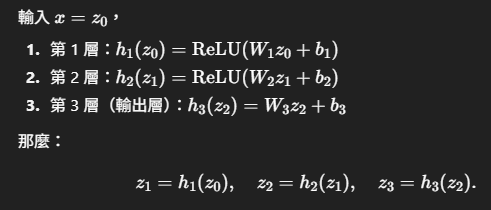

In [5]:
print('Cartpole Controller')

# Load the NNet file and pass a nominal input to get the class logits
# nnet_filename = '/content/drive/MyDrive/cartpole_nnet.nnet'
nominal_input = torch.Tensor([[0., 0.1, 0.2, 0.3]]) # these 4 values correspond to the 4 states in cartpole
# cart position/ cart velocity/ pole angle/ pole angular velocity
model = nnet_to_pytorch(nnet_filename)
Ws, bs = model_to_weights_and_biases(model)
nominal_output = model(nominal_input)
# in 4-> 16-> 16-> 16-> 2(no Relu)
print(f'\n{nominal_input=}')
print(f'{nominal_output=}')

# Also set up an example set of possible inputs to this NN
#epsilon = 0.1 # epsilon can be a scalar or a vec w/ same shape as nominal_input
#input_range = nominal_and_epsilon_to_range(nominal_input, epsilon)
#print(f'{input_range=}')

Cartpole Controller

nominal_input=tensor([[0.0000, 0.1000, 0.2000, 0.3000]])
nominal_output=tensor([[12.9007, -1.4208]], grad_fn=<AddmmBackward0>)


2 outputs: 12.9007 and -1.4208
- These are the network’s logits / scores (in the Cartpole setting, they correspond to two possible actions;
- **in HW we treat it like a classifier**

# Problem 1: Sampling-Based Under-Approximations

One way to approximate the set of possible NN outputs for a given set of possible NN inputs is by exhaustively sampling. Here, you will **implement a simple sampling-based method for estimating the min and max values for each dimension of the NN output**. This sampling-based strategy **provides an under-approximation of the output set** (and the corresponding rectangular bound is an under-approximation of the axis-aligned bounding box around the true output set).

The **cartpole NN only has 4 inputs and 2 outputs**, so you can visualize its output samples easily.

**Deliverables**:

- Implement the `output_range_sampling` function
- For the cartpole NN, plot your output samples and the corresponding rectangular bounds for a few different values of `num_samples`

NumPy 取樣 → Torch 前向 → NumPy 聚合

### 1.1) Implement the `output_range_sampling` function

In [6]:
def output_range_sampling(nnet_filename: str, in_range: np.ndarray, num_samples: int, return_flag = False):

  model = nnet_to_pytorch(nnet_filename) # load model
  model.eval() # set the model to evaluation mode

  #print(f'{in_range.shape=}')
  lower_bound = in_range[:, 0] # lower bound
  upper_bound = in_range[:, 1] # upper bound
  #print(f'{lower_bound.shape=}')
  #print(f'{upper_bound.shape=}\n')
  np.random.seed(0)
  lintf = np.random.uniform(low=lower_bound, high=upper_bound, size=(num_samples, lower_bound.shape[0]))# linear transform to [lower_bound, upper_bound] box
  #print(f'{lintf[:10]=}')
  #print(f'{lintf.shape=}\n')
  lintf_t = torch.tensor(lintf, dtype=torch.float32)
  #print(f'{lintf_t.shape=}\n')

  with torch.no_grad():
      out_t = model(lintf_t).numpy()

  #print(f'{out_t.shape=}')
  #print(f'\n--- output_range_sampling ---\n{out_t[:5]=}\n')

  min_max = np.stack([out_t.min(axis = 0), out_t.max(axis = 0)], axis=1)
  print(f'\n--- output_range_sampling ---\n{min_max=}\n')
  #print(f'{min_max.shape=}')

  # #print(f'{out_t.shape=}')
  # #print(f'\n--- output_range_sampling ---\n{out_t[:5]=}\n')
  # min_max = []
  # print(f'{out_t.min(axis = 0)=}', '\n', f'{out_t.max(axis = 0)=}')
  # min_max.append(out_t.min(axis = 0))
  # min_max.append(out_t.max(axis = 0))

  if return_flag:
    return min_max, lintf, out_t
  return min_max

epsilon = 0.1 # epsilon can be a scalar or a vec w/ same shape as nominal_input
input_range = nominal_and_epsilon_to_range(nominal_input, epsilon)
print(f'{epsilon=}', f'{input_range=}')
num_samples = int(10000)
output_range_sampling(nnet_filename, input_range, num_samples)

epsilon=0.1 input_range=array([[-0.1       ,  0.1       ],
       [ 0.        ,  0.2       ],
       [ 0.1       ,  0.3       ],
       [ 0.20000002,  0.4       ]], dtype=float32)

--- output_range_sampling ---
min_max=array([[11.31133  , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)



array([[11.31133  , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)

### 1.2) PLOT

In [7]:
def plot_samples(nnet_filename, in_range, sample_list):
  model = nnet_to_pytorch(nnet_filename)
  model.eval()

  for n in sample_list:
    min_max, lintf, out_t = output_range_sampling(nnet_filename, in_range, n, True)
    print(f'\nN = {n} \nbounds = {min_max}')

    plt.figure(figsize = (7, 7))
    plt.scatter(out_t[:, 0], out_t[:, 1], s = 1, alpha = 0.3)
    x0,x1 = min_max[0,0], min_max[0,1]
    y0,y1 = min_max[1,0], min_max[1,1]
    plt.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color = 'green')
    plt.title(f'(N = {n} ) output samples & rectangle')
    plt.xlabel('Dim 0(x)')
    plt.ylabel('Dim 1(y)')
    plt.show()

epsilon=0.1 input_range=array([[-0.1       ,  0.1       ],
       [ 0.        ,  0.2       ],
       [ 0.1       ,  0.3       ],
       [ 0.20000002,  0.4       ]], dtype=float32)

--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)


N = 1000 
bounds = [[11.541282  16.04846  ]
 [-3.9372277 -1.1029317]]


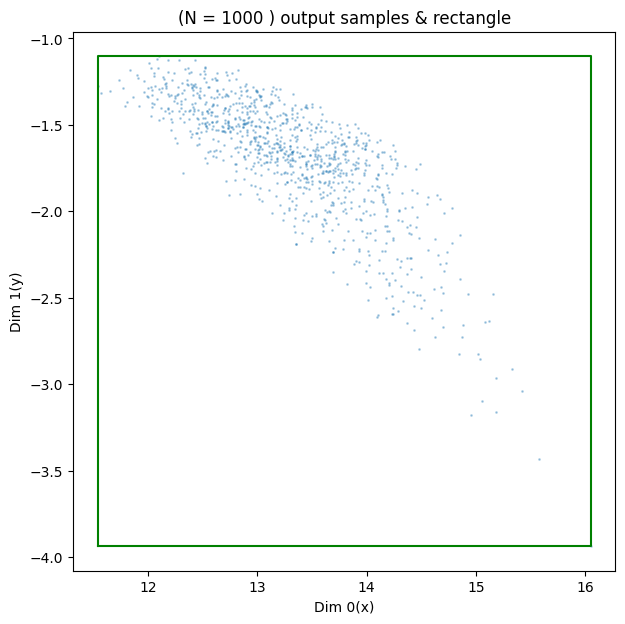


--- output_range_sampling ---
min_max=array([[11.363704 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)


N = 5000 
bounds = [[11.363704  16.04846  ]
 [-3.9372277 -1.1029317]]


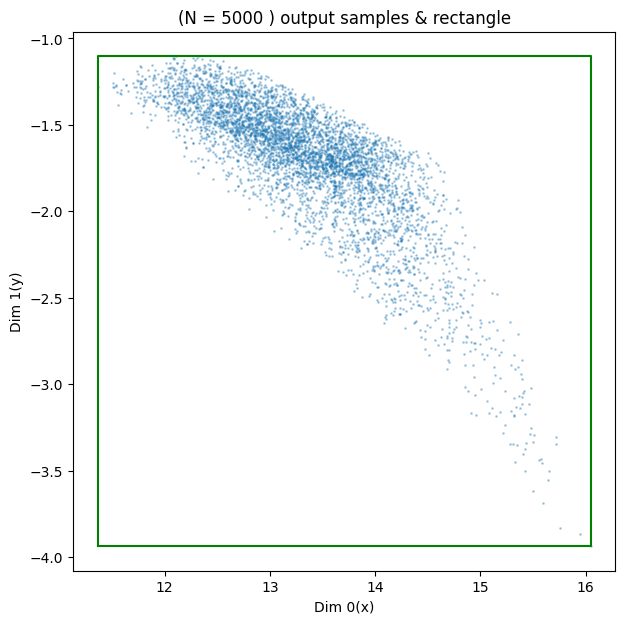


--- output_range_sampling ---
min_max=array([[11.31133  , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)


N = 10000 
bounds = [[11.31133   16.04846  ]
 [-3.9372277 -1.1029317]]


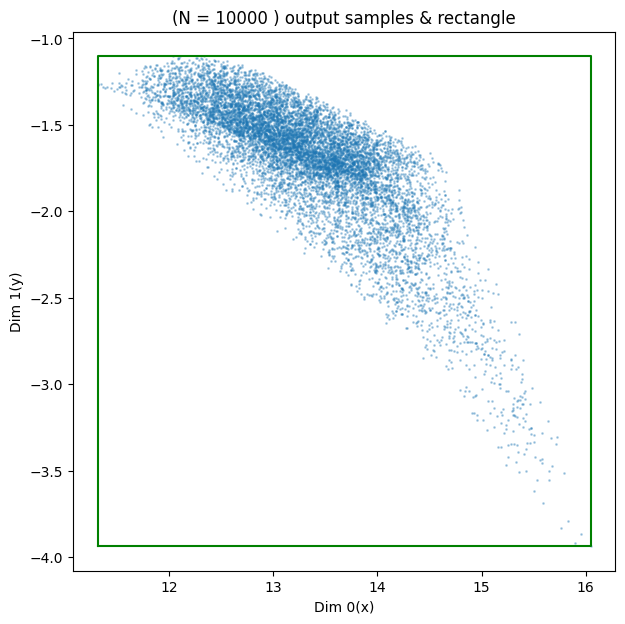


--- output_range_sampling ---
min_max=array([[11.303885 , 16.183311 ],
       [-4.056096 , -1.0913188]], dtype=float32)


N = 50000 
bounds = [[11.303885  16.183311 ]
 [-4.056096  -1.0913188]]


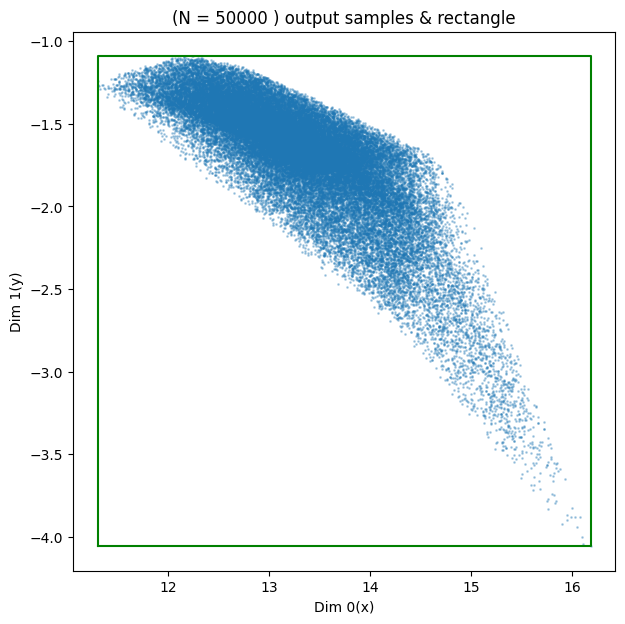


--- output_range_sampling ---
min_max=array([[11.265327 , 16.183311 ],
       [-4.056096 , -1.0913188]], dtype=float32)


N = 100000 
bounds = [[11.265327  16.183311 ]
 [-4.056096  -1.0913188]]


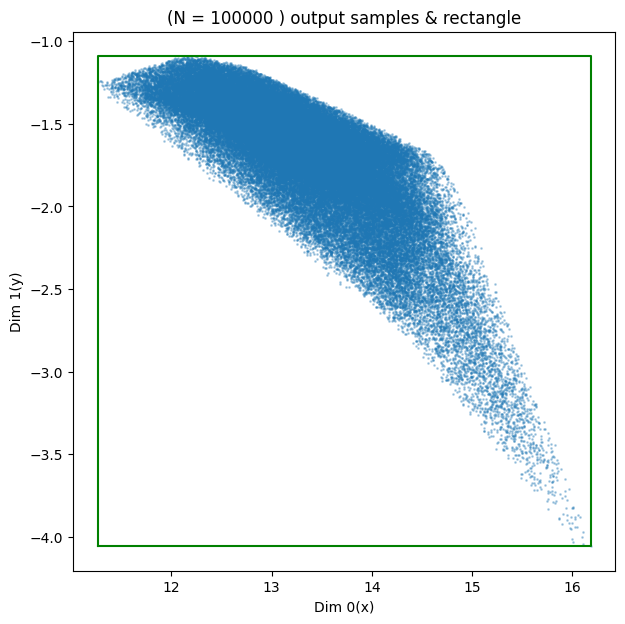

In [8]:
epsilon = 0.1 # epsilon can be a scalar or a vec w/ same shape as nominal_input
input_range = nominal_and_epsilon_to_range(nominal_input, epsilon)
print(f'{epsilon=}', f'{input_range=}')
plot_samples(nnet_filename,input_range,[1000, 5000, 10000, 50000, 100000])

# Check the meaning of x, y axis

In [9]:
test_cases = [
    # [position, velocity, angle, angular_velocity]
    [2.0, 0., 0., 0.],    # 車已經在右邊
    [-2.0, 0., 0., 0.],   # 車已經在左邊
    [0., 2.0, 0., 0.],    # 車正在往右移動
    [0., -2.0, 0., 0.],   # 車正在往左移動
]
cart_model = nnet_to_pytorch(nnet_filename)
cart_model.eval()

for state in test_cases:
    input_tensor = torch.Tensor([state])
    output = cart_model(input_tensor)
    print(f"State: {state}")
    print(f"Output: {output.detach().numpy()}")
    print(f"Action 0 logit: {output[0,0].item():.4f}")
    print(f"Action 1 logit: {output[0,1].item():.4f}")
    print(f"選擇動作: {'Action 0' if output[0,0] > output[0,1] else 'Action 1'}")
    print("---")

State: [2.0, 0.0, 0.0, 0.0]
Output: [[ 18.276567 -12.293028]]
Action 0 logit: 18.2766
Action 1 logit: -12.2930
選擇動作: Action 0
---
State: [-2.0, 0.0, 0.0, 0.0]
Output: [[-34.054325 -26.590069]]
Action 0 logit: -34.0543
Action 1 logit: -26.5901
選擇動作: Action 1
---
State: [0.0, 2.0, 0.0, 0.0]
Output: [[  8.449436 -27.380901]]
Action 0 logit: 8.4494
Action 1 logit: -27.3809
選擇動作: Action 0
---
State: [0.0, -2.0, 0.0, 0.0]
Output: [[-52.918102 -31.40059 ]]
Action 0 logit: -52.9181
Action 1 logit: -31.4006
選擇動作: Action 1
---


# Problem 2: Interval Bound Propagation (IBP)
## NOT YET: **[optimize the plot!]**
Now, you will implement the IBP algorithm to get *outer* bounds on the output set -- which are much more useful for proving that the NN will not produce undesired outputs. You may want to read [the IBP paper](https://arxiv.org/pdf/1810.12715.pdf) (especially around Eqn 6) to help with this.

**Deliverables:**

- Implement the `verify_ibp` function
- Print the `output_range` from your IBP implementation
- Plot your IBP rectangular bounds along with the samples from above to see how ridiculously loose IBP bounds can be

the IBP paper:
$z_k​=Wz_{k−1}​ + \ b$

### A few about paper [IBP](https://chatgpt.com/s/t_68dea78070ec81918464607b54bff162)

Variables:

- input $z_0$
- output $z_k$, $z_K \in \mathbf{R}^N $
- $N$ logits, $K$ layers
- a sequence of transformations $h_k$


$ \Rightarrow z_k = h_k(x_{k-1})$, $k = 1, \cdots, K$


Formula Used here:
- Affine Layers

  $\mu_{k-1} = \frac{( \overline{z}_{k-1} + \underline{z}_{k-1})} 2$

  $r_{k-1} = \frac{( \overline{z}_{k-1} - \underline{z}_{k-1})} 2$

  $\mu_{k} = \mathbf{W} \mu_{k-1}+ b$

  $r_{k} = |\mathbf{W}| r_{k-1}$

  $\underline{z}_{k} = \mu_{k} - r_k \ \ ② = h_k(\underline{z}_{k-1})$

  $\overline{z}_{k} = \mu_{k} + r_k \ \ ② = h_k(\overline{z}_{k-1})$

(if $h_k$ is an element-wise increasing function, ② is TRUE)

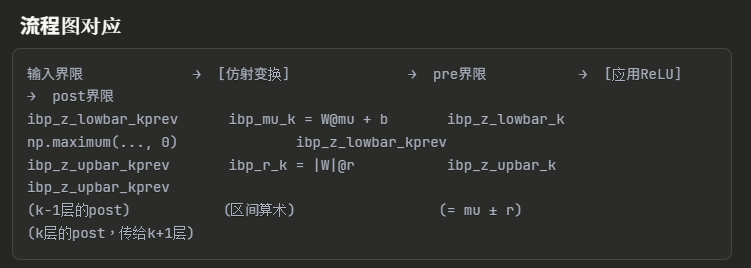

In [10]:
def verify_ibp(nnet_filename: str, ibp_in_range: np.ndarray):

  print('\n\n--- verify_ibp ---')

  ibp_ws, ibp_bs = nnet_to_weights_and_biases(nnet_filename)
  #print(f'{in_range.shape=}')
  #print(f'{in_range=}')

  # bounding box
# 【输入界限】(上一层的 post-activation 界限)
  ibp_z_lowbar_kprev = ibp_in_range[:, 0] # lowbar z0 = x0 - ϵ1
  ibp_z_upbar_kprev = ibp_in_range[:, 1] # upbar z0 = x0 + ϵ1
  #print('z0=', f'{z_lowbar_kprev.shape=}', f'{z_upbar_kprev.shape=}')

  #print('\n==== start loop ===')
  #print(f'{len(Ws)=}')
  for i in range(len(ibp_ws) - 1):         # without the last layer
    #print(' ----', {i}, '---')
    ibp_w, ibp_b = ibp_ws[i], ibp_bs[i]
    #print(f'{W.shape=}', f'{b.shape=}')

    ibp_mu_kprev = ( ibp_z_upbar_kprev + ibp_z_lowbar_kprev )/ 2  # center
    ibp_r_kprev = ( ibp_z_upbar_kprev - ibp_z_lowbar_kprev )/ 2  # radius
    #print(f'{mu_kprev.shape=}', f'{r_kprev.shape=}')
    #print(f'{mu_kprev=}\n', f'{r_kprev=}')

    ibp_mu_k = ibp_w @ ibp_mu_kprev + ibp_b # 传播中心
    ibp_r_k = np.abs(ibp_w) @ ibp_r_kprev # 传播半径
    #print(f'{mu_k.shape=}', f'{r_k.shape=}')
    #print(f'{mu_k=}\n', f'{r_k=}')
    ibp_z_upbar_k = ibp_mu_k + ibp_r_k# pre 上界
    ibp_z_lowbar_k = ibp_mu_k - ibp_r_k# pre 下界

    ibp_z_upbar_kprev = np.maximum(ibp_z_upbar_k, 0)# ReLU(pre下界)
    ibp_z_lowbar_kprev = np.maximum(ibp_z_lowbar_k, 0)# ReLU(pre上界)

  #print('\n--- the last layer ---')
  #print(' ----', {i+1}, '---')
  # the last layer
  ibp_w_last, ibp_b_last = ibp_ws[i+1], ibp_bs[i+1]

  ibp_mu_kprev = ( ibp_z_upbar_kprev + ibp_z_lowbar_kprev )/ 2  # center
  ibp_r_kprev = ( ibp_z_upbar_kprev - ibp_z_lowbar_kprev )/ 2  # radius
  #print(f'{mu_kprev.shape=}', f'{r_kprev.shape=}')
  #print(f'{mu_kprev=}\n', f'{r_kprev=}')

  ibp_mu_k = ibp_w_last @ ibp_mu_kprev + ibp_b_last
  ibp_r_k = np.abs(ibp_w_last) @ ibp_r_kprev
  #print(f'{ibp_mu_k.shape=}', f'{ibp_r_k.shape=}')
  #print(f'{ibp_mu_k=}\n', f'{ibp_r_k=}')
  ibp_z_upbar_k = ibp_mu_k + ibp_r_k
  ibp_z_lowbar_k = ibp_mu_k - ibp_r_k
  print('- ibp bound:')
  print(f'{ibp_z_upbar_k= }')
  print(f'{ibp_z_lowbar_k= }\n')

  return ibp_z_lowbar_k, ibp_z_upbar_k

In [11]:
eps = np.array([0.05, 0.1, 0.2, 0.3])
for i in range(len(eps)):
  input_range = nominal_and_epsilon_to_range(nominal_input, eps[i])
  print(f'{i=}', ' ', f'{input_range=}')
  output_range_ibp = verify_ibp(nnet_filename, input_range)
  #print(f'{output_range_ibp.shape=}')
  print(f'{output_range_ibp=}\n\n')

i=0   input_range=array([[-0.05      ,  0.05      ],
       [ 0.05      ,  0.15      ],
       [ 0.15      ,  0.25      ],
       [ 0.25      ,  0.35000002]], dtype=float32)


--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([30.31776224,  9.7058196 ])
ibp_z_lowbar_k= array([ -1.05745466, -15.22126055])

output_range_ibp=(array([ -1.05745466, -15.22126055]), array([30.31776224,  9.7058196 ]))


i=1   input_range=array([[-0.1       ,  0.1       ],
       [ 0.        ,  0.2       ],
       [ 0.1       ,  0.3       ],
       [ 0.20000002,  0.4       ]], dtype=float32)


--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([52.51911865, 23.75044591])
ibp_z_lowbar_k= array([-25.60730514, -32.45794935])

output_range_ibp=(array([-25.60730514, -32.45794935]), array([52.51911865, 23.75044591]))


i=2   input_range=array([[-0.2       ,  0.2       ],
       [-0.1       ,  0.3       ],
       [ 0.        ,  0.4       ],
       [ 0.10000001,  0.5       ]], dtype=float32)


--- verify_ibp ---
-

## 2.3) PLOT IBP rectangular bounds along with the samples from above

In [12]:
def plot_rect(min_x, max_x, min_y, max_y, coloring = 'orange', linwid = 2):
  plt.plot([min_x, max_x, max_x, min_x, min_x],
           [min_y, min_y, max_y, max_y, min_y],
           color = coloring, linewidth = linwid)

In [13]:
def plot_ibp(nnet_filename, in_range, sample_numbers=None):

    # 3) IBP 算輸出上下界
    ibp_low, ibp_up = verify_ibp(nnet_filename, in_range)   # 你在 Problem 2 要寫的函式，回傳 (l, u)

    outs = None
    if sample_numbers is not None and sample_numbers > 0:
        ibplot_samp_minmax, _, outs = output_range_sampling(nnet_filename, in_range, sample_numbers, True)

    # 5) 畫圖：樣本 + IBP 矩形
    plt.figure(figsize=(5,5))
    if outs is not None:
        plt.scatter(outs[:,0], outs[:,1], s = 0.2, alpha = 0.3)

    # ibp bound
    plot_rect(ibp_low[0], ibp_up[0], ibp_low[1],ibp_up[1], 'blue', 2)
    # sample bound
    if outs is not None:
        plot_rect(ibplot_samp_minmax[0,0], ibplot_samp_minmax[0,1], ibplot_samp_minmax[1,0], ibplot_samp_minmax[1,1], 'green', 1.5)

    plt.title('IBP output bounds' + (' + samples' if outs is not None else ''))
    plt.xlabel('logits'); plt.ylabel('Dim 1 (y)')
    plt.grid(True)


### FIXED sample=1000, change eps =[0.05, 0.1, 0.2, 0.3] **(DONE)**



--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([194.40266868, 114.85826718])
ibp_z_lowbar_k= array([-203.76416136, -149.37982995])



--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([30.31776224,  9.7058196 ])
ibp_z_lowbar_k= array([ -1.05745466, -15.22126055])


--- output_range_sampling ---
min_max=array([[12.191829 , 14.114109 ],
       [-2.2479858, -1.2509685]], dtype=float32)



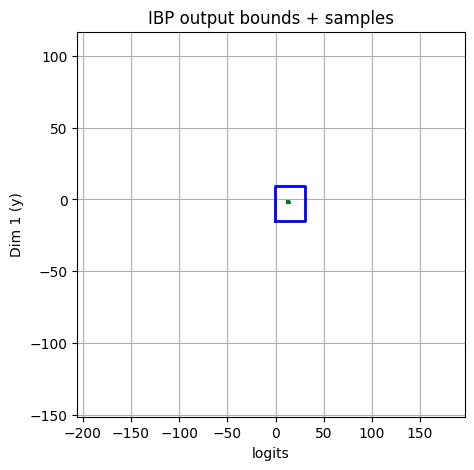



--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([52.51911865, 23.75044591])
ibp_z_lowbar_k= array([-25.60730514, -32.45794935])


--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)



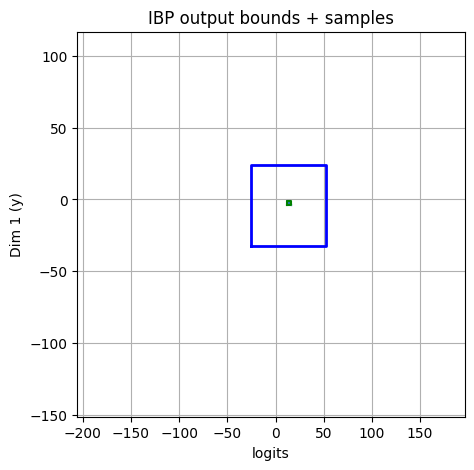



--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([107.45174852,  56.76783614])
ibp_z_lowbar_k= array([-81.83013197, -73.95964326])


--- output_range_sampling ---
min_max=array([[10.18309  , 18.110031 ],
       [-7.0023446, -0.866661 ]], dtype=float32)



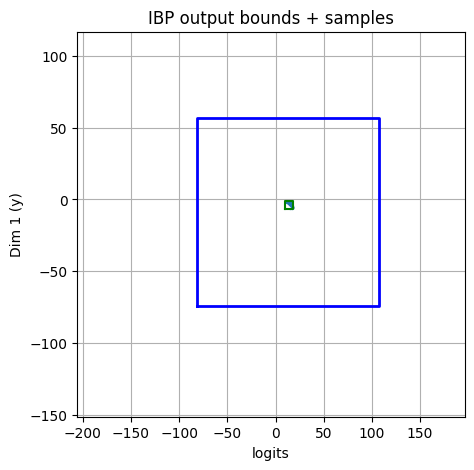



--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([194.40266868, 114.85826718])
ibp_z_lowbar_k= array([-203.76416136, -149.37982995])


--- output_range_sampling ---
min_max=array([[ 9.079754 , 19.286404 ],
       [-9.633265 , -0.5524078]], dtype=float32)



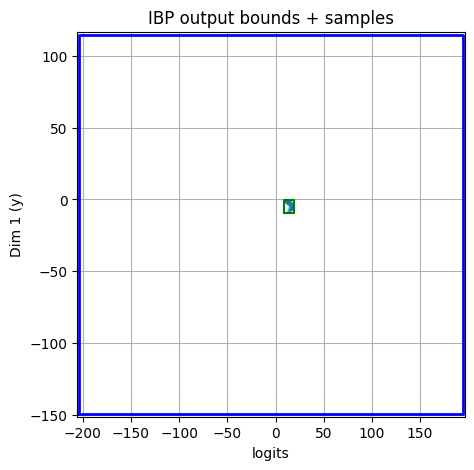

In [14]:
eps = np.array([0.05, 0.1, 0.2, 0.3])
max_eps = max(eps)

in_range_glob = nominal_and_epsilon_to_range(nominal_input, max_eps)
ibp_low_glob, ibp_up_glob = verify_ibp(nnet_filename, in_range_glob)
xlim = (ibp_low_glob[0]-2, ibp_up_glob[0]+2)
ylim = (ibp_low_glob[1]-2, ibp_up_glob[1]+2)

for i in range(len(eps)):
  plot_ibp(nnet_filename, nominal_and_epsilon_to_range(nominal_input, eps[i]), 1000)
  plt.xlim(xlim)
  plt.ylim(ylim)
  plt.show()

### FIXED eps =xxx, change sample=1000 **(NOT YET)**



--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([52.51911865, 23.75044591])
ibp_z_lowbar_k= array([-25.60730514, -32.45794935])


--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)

output_range_ibp=(array([-203.76416136, -149.37982995]), array([194.40266868, 114.85826718]))


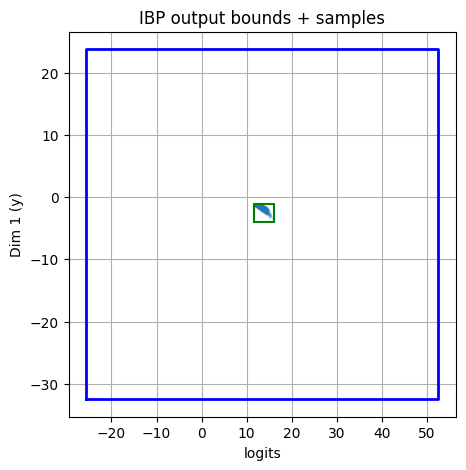

In [15]:
# set up an example set of possible inputs to this NN
epsilon = 0.1
plot_ibp(nnet_filename, nominal_and_epsilon_to_range(nominal_input, epsilon), 1000)
#print(f'{output_range_ibp.shape=}')
print(f'{output_range_ibp=}')



--- verify_ibp ---
- ibp bound:
ibp_z_upbar_k= array([52.51911865, 23.75044591])
ibp_z_lowbar_k= array([-25.60730514, -32.45794935])


--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)



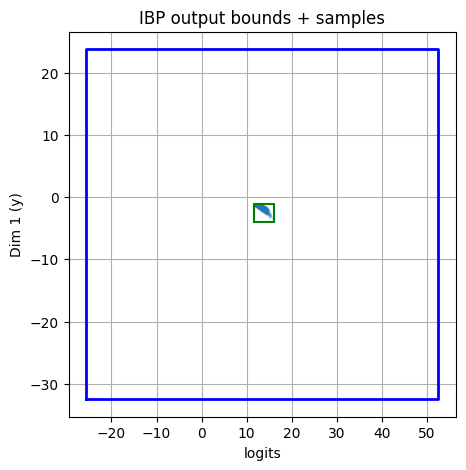

In [16]:
epsilon = 0.1
plot_ibp(nnet_filename, nominal_and_epsilon_to_range(nominal_input, epsilon), 1000)

# Problem 3: Linear Program (LP)

Since IBP's bounds are usually too loose to say something useful about the NN's output set, you will now implement an LP-based verification algorithm that should provide much tighter bounds while remaining computationally reasonable.

You will **set up an LP** (e.g., using `cvxpy` to set up variables, constraints, and objectives corresponding to the NN verification problem) for each side of the rectangle (i.e., min & max per output dimension, which can be done by simply changing the objective). To **turn the ReLU constraints into linear equality/inequality constraints**, you can **check which neurons are 'active', 'inactive', or 'uncertain' and add the corresponding relaxed constraints**. To know which neurons belong to which category, you will need to acquire intermediate bounds -- there are lots of ways to do this!

choose a solver: [Solver Features](https://www.cvxpy.org/tutorial/solvers/)

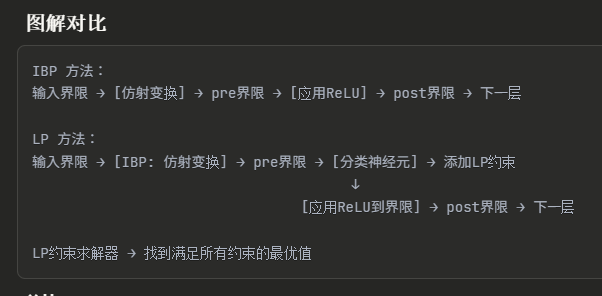

In [17]:
def verify_lp(nnet_filename: str, lp_in_range: np.ndarray) -> np.ndarray:
  lp_ws, lp_bs = nnet_to_weights_and_biases(nnet_filename)

  lp_n_layers = len(lp_ws)
  lp_n_in = lp_in_range.shape[0]
  lp_n_out = lp_ws[-1].shape[0]


  lp_z_post_act = []
  lp_z_post_act.append(cp.Variable(lp_n_in)) # Input layer
  for i in range(lp_n_layers - 1): # Hidden layer
    lp_z_post_act.append(cp.Variable(lp_ws[i].shape[0]))
  lp_z_post_act.append(cp.Variable(lp_n_out)) # Output layer (no ReLU)

  lp_constraints = []
  lp_constraints.append(lp_z_post_act[0] >= lp_in_range[:, 0])
  lp_constraints.append(lp_z_post_act[0] <= lp_in_range[:, 1])

  lp_z_lowbar_kprev = lp_in_range[:, 0] # lowbar z0 = x0 - ϵ1
  lp_z_upbar_kprev = lp_in_range[:, 1] # upbar z0 = x0 + ϵ1

  for i in range(len(lp_ws) - 1):         # without the last layer
    #print(' ----', {i}, '---')
    lp_w, lp_b = lp_ws[i], lp_bs[i]
    #print(f'{W.shape=}', f'{b.shape=}')

    lp_mu_kprev = ( lp_z_upbar_kprev + lp_z_lowbar_kprev )/ 2  # center
    lp_r_kprev = ( lp_z_upbar_kprev - lp_z_lowbar_kprev )/ 2  # radius
    #print(f'{mu_kprev.shape=}', f'{r_kprev.shape=}')
    #print(f'{mu_kprev=}\n', f'{r_kprev=}')

    lp_mu_k = lp_w @ lp_mu_kprev + lp_b
    lp_r_k = np.abs(lp_w) @ lp_r_kprev
    #print(f'{mu_k.shape=}', f'{r_k.shape=}')
    #print(f'{mu_k=}\n', f'{r_k=}')
    lp_z_upbar_k = lp_mu_k + lp_r_k
    lp_z_lowbar_k = lp_mu_k - lp_r_k

    #lp_constraints.appends()

    #print(f'{lp_z_post_act=}')
    pre_act = lp_w @ lp_z_post_act[i] + lp_b

    for j in range(len(lp_z_upbar_k)): # [l, u]
      lp_up = lp_z_upbar_k[j]
      lp_low = lp_z_lowbar_k[j]

      if lp_low >= 0: # active
        #print('ACT ',  f'{j=}')
        lp_constraints.append(lp_z_post_act[i+1][j] == pre_act[j])
      elif lp_up <= 0: # inactive
        #print('INact ',  f'{j=}')
        lp_constraints.append(lp_z_post_act[i+1][j] == 0)
      else: # unsure
        #print('Un ',  f'{j=}')
        lp_constraints.append(lp_z_post_act[i+1][j] >= 0) # z >= 0
        lp_constraints.append(lp_z_post_act[i+1][j] >= pre_act[j]) # z >= pre_activation
        lp_constraints.append(lp_z_post_act[i+1][j] <= (lp_up/(lp_up-lp_low)) * (pre_act[j]-lp_low) ) # z <= u/(u-l) * (pre_activation - l)

    lp_z_upbar_kprev = np.maximum(lp_z_upbar_k, 0)
    lp_z_lowbar_kprev = np.maximum(lp_z_lowbar_k, 0)


  #print(f'{i=}' + ' ',  f'{j=}')
  lp_w_last, lp_b_last = lp_ws[-1], lp_bs[-1]
  #print(f"Layer {i}: W{lp_w_last.shape}, z{lp_z_post_act[i].shape}, b{lp_b_last.shape}")
  lp_constraints.append(lp_z_post_act[-1] == lp_w_last @ lp_z_post_act[-2] + lp_b_last)


  output_range = np.zeros((lp_n_out, 2))

  for k in range(lp_n_out):

    # find Minima
    lp_prob_min = cp.Problem(cp.Minimize(lp_z_post_act[-1][k]), lp_constraints)
    out_min = lp_prob_min.solve(solver=cp.HIGHS)
    output_range[k, 0] = out_min

    # find Maxima
    lp_prob_max = cp.Problem(cp.Maximize(lp_z_post_act[-1][k]), lp_constraints)
    out_max = lp_prob_max.solve(solver=cp.HIGHS)
    output_range[k, 1] = out_max

  return output_range

#verify_lp(nnet_filename, input_range)
output_range_lp = verify_lp(nnet_filename, input_range)
print(f'{output_range_lp=}')

output_range_lp=array([[-66.52871105,  78.04629071],
       [-50.04970937,  38.31686681]])


# Problem 4: Verify Classifier Robustness

So far, you have written verification algorithms that provide upper and lower bounds on each output of the NN. Here, you will **slightly modify your LP verifier** so that it **verifies** the *robustness* of a *classifier* (i.e., prove that the classifier predicts the same class for every input within some range).

If the verification algorithm is able to prove robustness, you should return `VerifierResults.Robust`. If the verification algorithm is unable to prove robustness, you should return `VerifierResults.Unsure` (remember that this doesn't necessarily mean the classifier isn't robust, just that our algorithm failed to find a proof). I also added a `VerifierResults.Timeout` option, because you will often see this in real verification algorithms, but you do not need to use this here.

To start, you can pretend the cartpole controller was a classifier and try to see how large of an epsilon you can specify until you can't verify the robustness anymore.

Then, you can load an MNIST classifier (code below) and try to see how large of an epsilon for which you can still verify robustness around a nominal image. Since the MNIST classifier is a way bigger NN, there will be some impact on the runtime of your LP.

**Deliverables:**

- Implement `verify_classification_robustness_lp`
- Plot and/or briefly describe your findings w.r.t. robustness verification as you increase epsilon for the cartpole controller
- Plot and/or briefly describe your findings w.r.t. robustness verification as you increase epsilon for the MNIST classifier

In [18]:
class VerifierResults(Enum):
  Robust = 0
  Unsure = 1
  Timeout = 2

def verify_classification_robustness_lp(nnet_filename: str, rob_in_range: np.ndarray) -> int:

  rob_cent_in = (rob_in_range[:, 0] + rob_in_range[:, 1]) / 2
  rob_model = nnet_to_pytorch(nnet_filename)
  rob_model.eval()
  with torch.no_grad():
      rob_output = model(torch.tensor(rob_cent_in))
      pred_class = torch.argmax(rob_output)

    # 使用 LP 計算輸出界限
  rob_out_bounds = verify_lp(nnet_filename, rob_in_range)

    # 獲取 predicted_class 的下界
  pred_low = rob_out_bounds[pred_class, 0]


  # 檢查所有其他類別的上界是否都小於 predicted_lower
  for i in range(rob_out_bounds.shape[0]):
      if i != pred_class:
          other_upper = rob_out_bounds[i, 1]
          if other_upper >= pred_low:
              return VerifierResults.Unsure

  return VerifierResults.Robust

verifier_result = verify_classification_robustness_lp(nnet_filename, input_range)

Testing Cartpole Controller Robustness
Testing ε = 0.010... Robust
Testing ε = 0.050... Robust
Testing ε = 0.100... Unsure

→ Maximum robust ε ≈ 0.050


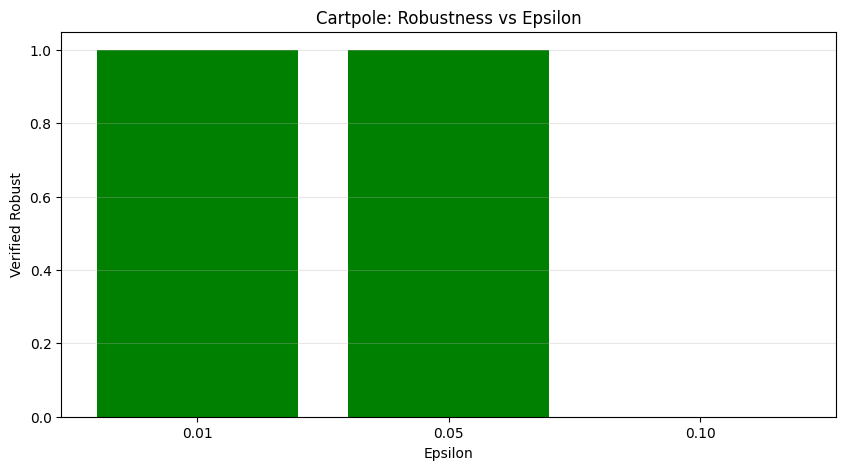

In [19]:
# ============================================
# Cartpole Controller 測試（簡潔版）
# ============================================
print("=" * 60)
print("Testing Cartpole Controller Robustness")
print("=" * 60)

epsilon_values = [0.01, 0.05, 0.1, 0.15, 0.2]
cartpole_results = []

for eps in epsilon_values:
    print(f"Testing ε = {eps:.3f}... ", end='')
    input_range = nominal_and_epsilon_to_range(nominal_input, eps)
    result = verify_classification_robustness_lp(nnet_filename, input_range)
    cartpole_results.append((eps, result))
    print(f"{VerifierResults(result).name}")

    if result == VerifierResults.Unsure:
        if len(cartpole_results) > 1:
            print(f"\n→ Maximum robust ε ≈ {cartpole_results[-2][0]:.3f}")
        break

# 畫圖
plt.figure(figsize=(10, 5))
eps_vals = [r[0] for r in cartpole_results]
robust_vals = [1 if r[1] == VerifierResults.Robust else 0 for r in cartpole_results]
plt.bar(range(len(eps_vals)), robust_vals,
        color=['green' if v == 1 else 'red' for v in robust_vals])
plt.xticks(range(len(eps_vals)), [f'{e:.2f}' for e in eps_vals])
plt.xlabel('Epsilon')
plt.ylabel('Verified Robust')
plt.title('Cartpole: Robustness vs Epsilon')
plt.grid(axis='y', alpha=0.3)
plt.show()

Testing Cartpole Controller Robustness
Testing ε = 0.010... Robust
Testing ε = 0.050... Robust
Testing ε = 0.080... Robust
Testing ε = 0.090... Unsure
Testing ε = 0.100... Unsure
Testing ε = 0.150... Unsure
Testing ε = 0.200... Unsure
Testing ε = 0.250... Unsure


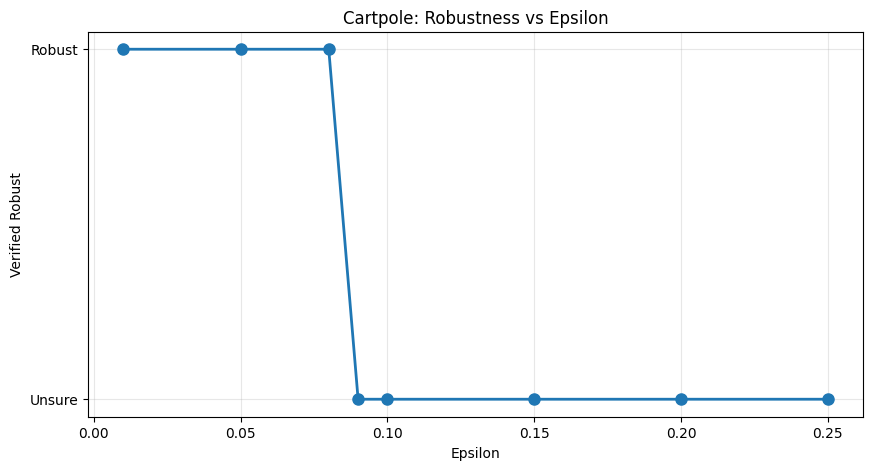

In [20]:
print("=" * 60)
print("Testing Cartpole Controller Robustness")
print("=" * 60)

rob_eps_list = [0.01, 0.05, 0.08, 0.09, 0.1, 0.15, 0.2, 0.25]
cartpole_results = []

for e in rob_eps_list:
    print(f"Testing ε = {e:.3f}... ", end='')
    rob_input_range = nominal_and_epsilon_to_range(nominal_input, e)
    rob_result = verify_classification_robustness_lp(nnet_filename, rob_input_range)
    cartpole_results.append((e, rob_result))
    print(f"{VerifierResults(rob_result).name}")

# 畫圖
plt.figure(figsize=(10, 5))
eps_vals = [r[0] for r in cartpole_results]
robust_vals = [1 if r[1] == VerifierResults.Robust else 0 for r in cartpole_results]

plt.plot(eps_vals, robust_vals, 'o-', linewidth=2, markersize=8)
plt.xlabel('Epsilon')
plt.ylabel('Verified Robust')
plt.title('Cartpole: Robustness vs Epsilon')
plt.yticks([0, 1], ['Unsure', 'Robust'])
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
print('MNIST Classifier')

# Load the NNet file and pass a nominal input to get the class logits
nnet_filename_mnist = '/content/drive/MyDrive/mnist1.nnet'

from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

img_index = 2 # this one should be correctly classified as a 4...
nominal_input_mnist = torch.Tensor(x_train[img_index].flatten())

model_mnist = nnet_to_pytorch(nnet_filename_mnist)
Ws_mnist, bs_mnist = model_to_weights_and_biases(model_mnist)
nominal_output = model_mnist(nominal_input_mnist)
nominal_class = nominal_output.argmax()
print(f'{nominal_output=}')
print(f'Predicted Class: {nominal_class}, True Class: {y_train[img_index]}')

# Also set up an example set of possible inputs to this NN

epsilon_mnist = 2*np.ones((784), dtype=np.float32)
input_range_mnist = nominal_and_epsilon_to_range(nominal_input_mnist, epsilon_mnist)
print(f'{input_range_mnist=}')

MNIST Classifier
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
nominal_output=tensor([ -130.8385, -1543.3896,   131.6747,   348.4881,   987.1153, -1114.0829,
         -638.6053,   216.2303,   -85.5049,   418.8904],
       grad_fn=<ViewBackward0>)
Predicted Class: 4, True Class: 4
input_range_mnist=array([[-2.,  2.],
       [-2.,  2.],
       [-2.,  2.],
       ...,
       [-2.,  2.],
       [-2.,  2.],
       [-2.,  2.]], dtype=float32)


/tmp/ipython-input-3451332994.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.vstack([nominal-epsilon, nominal+epsilon]).T


In [23]:
print("\n" + "=" * 60)
print("Testing MNIST Classifier Robustness")
print("=" * 60)

epsilon_values = [0.5, 1.0, 1.5, 2.0]
mnist_results = []

for eps in epsilon_values:
    print(f"Testing ε = {eps:.2f}... ", end='')
    eps_vector = eps * np.ones(784, dtype=np.float32)
    input_range = nominal_and_epsilon_to_range(nominal_input_mnist, eps_vector)
    result = verify_classification_robustness_lp(nnet_filename_mnist, input_range)
    mnist_results.append((eps, result))
    print(f"{VerifierResults(result).name}")

# 畫圖
plt.figure(figsize=(10, 5))
eps_vals = [r[0] for r in mnist_results]
robust_vals = [1 if r[1] == VerifierResults.Robust else 0 for r in mnist_results]

plt.plot(eps_vals, robust_vals, 'o-', linewidth=2, markersize=8)
plt.xlabel('Epsilon')
plt.ylabel('Verified Robust')
plt.title(f'MNIST (Image {img_index}): Robustness vs Epsilon')
plt.yticks([0, 1], ['Unsure', 'Robust'])
plt.grid(True, alpha=0.3)
plt.show()


Testing MNIST Classifier Robustness
Testing ε = 0.50... 

/tmp/ipython-input-3451332994.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.vstack([nominal-epsilon, nominal+epsilon]).T


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x784 and 4x16)

Load a NN classifier for MNIST, then query the model at a particular image:

1. 載入 MNIST 資料

   ↓

2. 選擇一張圖片（索引 2，數字 4）

   ↓

3. 將圖片攤平: (28,28) → (784,)

   ↓

4. 載入神經網路模型

   ↓

5. 預測該圖片 → 確認分類正確（預測=4, 真實=4）

   ↓

6. 定義擾動範圍: 每個像素 ±2

   ↓
   
7. 準備好進行魯棒性驗證！

In [24]:
eps = [0.5, 0.6, 0.7, 0.8, 0.9, 1]

for e in eps:
  print("Epsilon: ", e)
  input_range = nominal_and_epsilon_to_range(nominal_input, e)
  output_range_lp = verify_classification_robustness_lp(nnet_filename_mnist, input_range)
  print(output_range_lp, "\n\n")

Epsilon:  0.5


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 4 is different from 784)

In [ ]:
verifier_result = verify_classification_robustness_lp(nnet_filename_mnist, input_range_mnist)

# Problem 5: Explore the `jax_verify` library for verification

There are a few excellent open-source libraries for NN verification. For example, `jax_verify` has implementations of IBP, CROWN, and many other algorithms. These methods can handle a broader class of NNs than just the ReLU NNs you worked with above, so they may be useful tools to leverage in your research or projects.

A big upside of `jax_verify` is that it supports JIT compilation, which can speed up verification algorithms by 10-100x (you don't need to set up JIT compilation for this assignment, but you're encouraged to try that out if you're curious).

Note that the `jax_verify` that is available by default in PyPi is an old version from 2020 that has a slightly different API - installing a more recent version is recommended as we do below.

In [ ]:
# Install my fork of jax_verify, which fixes a few deprecation errors in the mainline repopip
!pip install git+https://gitlab.com/neu-autonomy/certifiable-learning/jax_verify@c9dedb6a60a84a9262d07d1a7efa67106649ece8

In [ ]:
import jax.numpy as jnp
import jax_verify
import functools

Some utility methods that help set up the NN in jax:

In [ ]:
def pytorch_model_to_jax(torch_model: torch.nn.Sequential):
  params = []
  act = None

  # Extract params (weights, biases) from torch layers, to be used in
  # jax.
  # Note: This propagator assumes a feed-forward relu NN.
  for m in torch_model.modules():
    if isinstance(m, torch.nn.Sequential):
      continue
    elif isinstance(m, torch.nn.ReLU):
      if act is None or act == 'relu':
        act = 'relu'
    elif isinstance(m, torch.nn.Linear):
      w = m.weight.data.numpy().T
      b = m.bias.data.numpy()
      params.append((w, b))
  return functools.partial(relu_nn, params)

def relu_nn(params, inputs):
  for W, b in params[:-1]:
    outputs = jnp.dot(inputs, W) + b
    inputs = jnp.maximum(outputs, 0)
  W, b = params[-1]
  return jnp.dot(inputs, W) + b

def jax_interval_to_np_range(interval: jax_verify.IntervalBound) -> np.ndarray:
  return np.vstack([interval.lower, interval.upper]).T

def np_range_to_jax_interval(input_range: np.ndarray) -> jax_verify.IntervalBound:
  return jax_verify.IntervalBound(input_range[:, 0], input_range[:, 1])

jax_model = pytorch_model_to_jax(model)

An example of using jax_verify's implementation of IBP on our cartpole control NN

In [ ]:
# Example of a fwd pass on the NN using jax
nominal_output_jax = jax_model(jnp.array(nominal_input))

# Example of computing bounds using IBP as implemented by jax_verify
print(f'{input_range}')
input_bounds = np_range_to_jax_interval(input_range)
print(f'{input_bounds}')
output_bounds_ibp_jax = jax_verify.interval_bound_propagation(
    jax_model, input_bounds)
output_range_ibp_jax = jax_interval_to_np_range(output_bounds_ibp_jax)
print(f'output bounds via IBP (jax_verify): \n{output_range_ibp_jax}')

Does that output match the output of your IBP implementation? **Yes!!!** **It works!!**

Now for your job: take a look at jax_verify's documentation to see how to use the backward CROWN verifier.

**Deliverables:**

- output bounds using backward CROWN, rather than IBP

In [ ]:
output_bounds_crown_jax = jax_verify.backward_crown_bound_propagation(
    jax_model, input_bounds)
output_bounds_crown_jax = jax_interval_to_np_range(output_bounds_crown_jax)
print(f"output bounds via backward Crown Bound (jax_verify): \n{output_bounds_crown_jax}")

# Problem 6: Explore the `auto-LiRPA` library for verification

`auto-LiRPA` is a verification library based on PyTorch and one of the main developers was a Northeastern PhD student (Kaidi Xu)!

Just like with the previous problem, the next cells show you how to install the package and run IBP, then we ask you to look into their documentation and run backward CROWN on the same problem.

**Note:** I suggest doing this part last, because pip may try to downgrade the version of pytorch installed to satisfy requirements. You may also need to restart your kernel after the pip install. If you're on Colab and things seem messed up, you can always do `Runtime > Disconnect and delete runtime` (stronger than restarting the runtime, which doesn't reset to the default set of installed packages).

In [25]:
!pip install git+https://github.com/Verified-Intelligence/auto_LiRPA

  Cloning https://github.com/Verified-Intelligence/auto_LiRPA to /tmp/pip-req-build-mks1lkbo
  Running command git clone --filter=blob:none --quiet https://github.com/Verified-Intelligence/auto_LiRPA /tmp/pip-req-build-mks1lkbo
  Resolved https://github.com/Verified-Intelligence/auto_LiRPA to commit cf0169ce6bfb4fddd82cfff5c259c162a23ad03c
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 337.4/337.4 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 307.2/307.2 kB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 84.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 523.5/523.5 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 M

An example of using jax_verify's implementation of IBP on our cartpole control NN:

In [26]:
from auto_LiRPA import BoundedModule, BoundedTensor, PerturbationLpNorm

# Wrap the model with auto_LiRPA.
model = BoundedModule(model, torch.Tensor(nominal_input))
# Define perturbation. Here we add Linf perturbation to input data.
ptb = PerturbationLpNorm(norm=np.inf, eps=torch.Tensor([epsilon]))
# Make the input a BoundedTensor with the pre-defined perturbation.
my_input = BoundedTensor(torch.Tensor(nominal_input), ptb)
# Regular forward propagation using BoundedTensor works as usual.
prediction = model(my_input)
# Compute LiRPA bounds using IBP
lb, ub = model.compute_bounds(x=(my_input,), method='ibp')
output_range_ibp_autolirpa = np.vstack([lb.detach().numpy(), ub.detach().numpy()]).T
print(f'output bounds via IBP (auto-lirpa): \n{output_range_ibp_autolirpa}')

ImportError: cannot import name '_CAFFE2_ATEN_FALLBACK' from 'torch._C._onnx' (unknown location)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Does that match your implementation of IBP? What about `jax_verify`'s?

**YES!!**

Now for your job: compute output bounds using `auto-LiRPA`'s implementation of backward CROWN

**Deliverables:**

- output bounds using backward CROWN, rather than IBP

In [ ]:
lb, ub = model.compute_bounds(x=(my_input,), method='CROWN')
output_range_CROWN_autolirpa = np.vstack([lb.detach().numpy(), ub.detach().numpy()]).T
print(f'output bounds via CROWN (auto-lirpa): \n{output_range_CROWN_autolirpa}')

All done!